# Speech processing pipeline analysis

- WER by duration
- WER by model
- Matches by type (?)
- Pipeline latencies compared:
  - Overall
  - By binned duration
  - By Whisper model
- Latency distribution
- Failed vs Correct vs Partial translations:
  - Overall
  - By Whisper model

In [47]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

In [3]:
df_csv = pd.read_csv("results.csv", index_col=0)
df_json = pd.read_json("results.json")

In [4]:
df_csv

,instance,reference,hypothesis,wer,overall_latency (s),listen_latency (s),filter_latency (s),normalize_latency (s),response_time (s),file_size,sample_rate,samples,duration (s),model
0,attack the alien.wav,attack the alien,NaN,NaN,0.253058,0.240149,0.000003,0.011898,0.627890,481852,48000,40155,2.51,tiny
1,attack the enemy on the left.wav,attack the enemy on the left,NaN,NaN,0.291567,0.273857,0.000004,0.016549,0.731320,319488,44100,57958,3.62,tiny
2,attack the enemy.wav,attack the enemy,NaN,NaN,0.253887,0.247242,0.000003,0.005681,0.650970,412732,48000,34395,2.15,tiny
3,attack the monster.wav,attack the monster,NaN,NaN,0.273983,0.251846,0.000004,0.021203,0.656101,668092,48000,55675,3.48,tiny
4,attack the red monster.wav,attack the red monster,NaN,NaN,0.268057,0.246046,0.000004,0.020865,0.650877,241664,44100,43840,2.74,tiny
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,stop right here.wav,stop right here,NaN,NaN,13.340707,13.319708,0.000005,0.018451,32.594572,188416,44100,34180,2.14,medium
196,stop.wav,stop,NaN,NaN,13.201487,13.199460,0.000004,0.000297,31.220116,337852,48000,28155,1.76,medium
197,use the door.wav,use the door,NaN,NaN,13.737459,13.689877,0.000009,0.045170,33.735484,422332,48000,35195,2.20,medium
198,use the gun.wav,use the gun,use the gun,0.166667,13.600162,13.582968,0.000004,0.015623,35.332734,408892,48000,34075,2.13,medium


## WER statistics

<Axes: title={'center': 'WER by duration of audio'}, xlabel='Duration (seconds)', ylabel='WER %'>

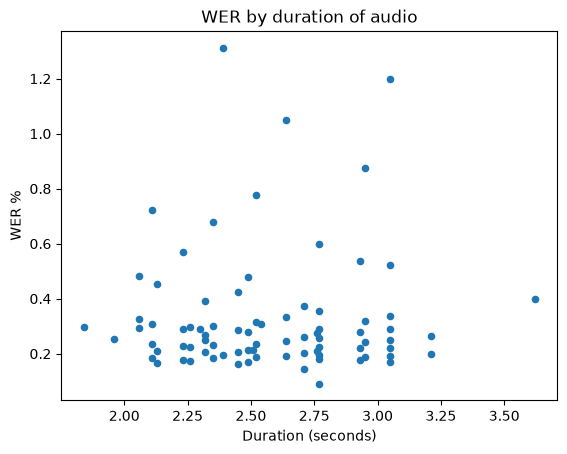

In [43]:
by_duration = df_csv.loc[:, ["wer", "duration (s)"]]

by_duration.plot.scatter(x="duration (s)", y="wer",
                         title="WER by duration of audio",
                         ylabel="WER %", xlabel="Duration (seconds)")

Text(0.5, 1.0, '')

Text(0.5, 1.0, '')

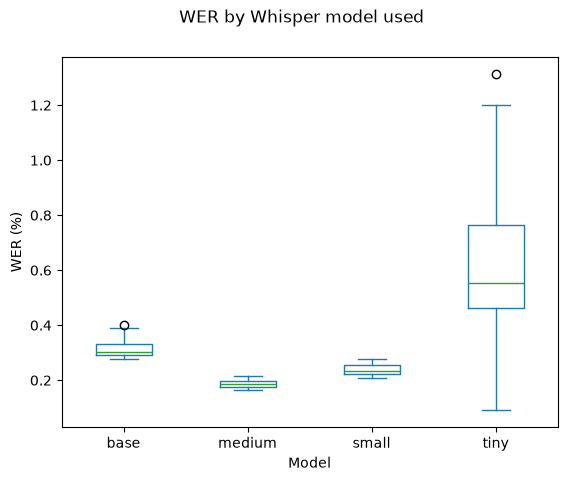

In [100]:
by_model = df_csv.loc[:, ["wer", "model"]]
axes = by_model.plot.box(by="model", title="WER by Whisper model used", xlabel="Model", ylabel="WER (%)")
axes.iloc[0].set_title("")

Text(0.5, 1.0, '')

Text(0.5, 1.0, '')

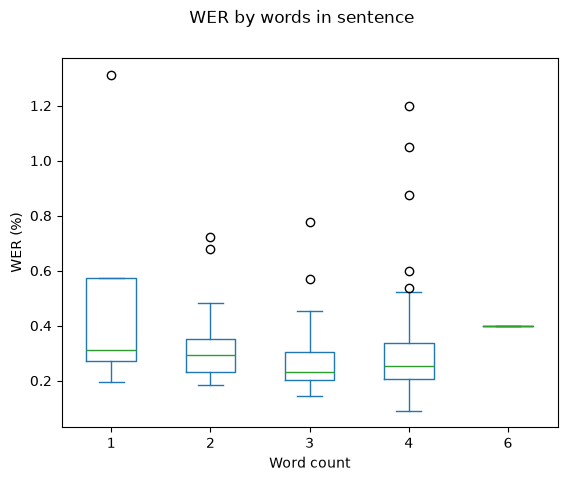

In [101]:
by_words = df_csv.loc[:, ["wer", "reference"]]
by_words["word_count"] = by_words["reference"].map(lambda sentence: len(sentence.split(" ")))

axes = by_words.plot.box(by="word_count", title="WER by words in sentence", xlabel="Word count", ylabel="WER (%)")
axes.iloc[0].set_title("")

## Transcription success

<Axes: title={'center': 'Transcription results by model'}, xlabel='Model', ylabel='Number of samples'>

<Axes: title={'center': 'Transcription results by model'}, xlabel='Model', ylabel='Number of samples'>

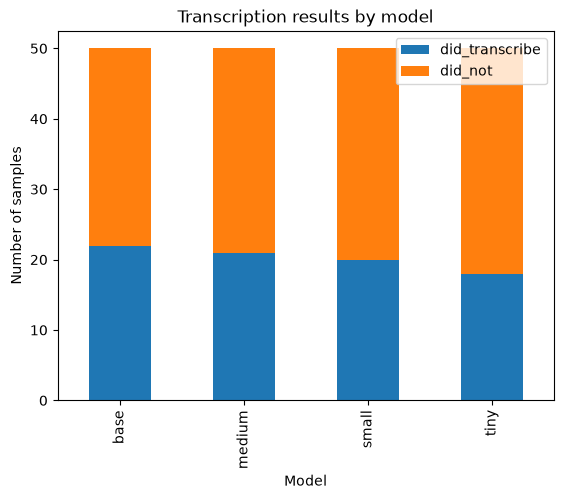

In [76]:
model_transcriptions = df_csv.loc[:, ["hypothesis", "reference", "model"]]

# Mask by transcription done
m = ~model_transcriptions["hypothesis"].isna()
model_transcriptions["did_transcribe"] = m
model_transcriptions["did_not"] = ~m

transcription_counts = model_transcriptions.groupby("model").sum().reset_index()
transcription_counts.plot.bar(
    x="model",
    y=["did_transcribe", "did_not"],
    stacked=True,
    title="Transcription results by model",
    xlabel="Model",
    ylabel="Number of samples",
 )

<Axes: title={'center': 'Transcription results by model'}, xlabel='Model', ylabel='Number of samples'>

<Axes: title={'center': 'Transcription results by model'}, xlabel='Model', ylabel='Number of samples'>

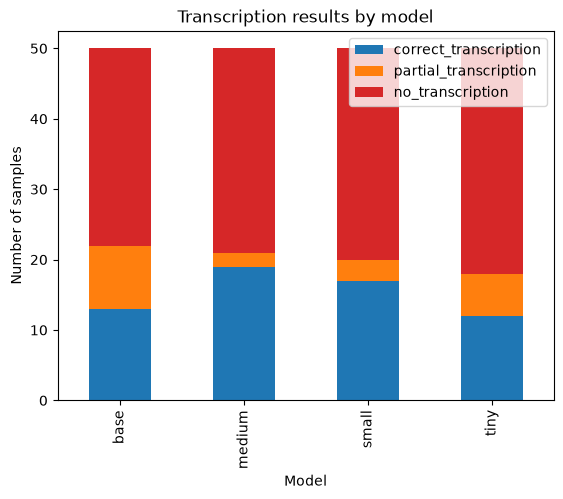

In [92]:
model_transcriptions = df_csv.loc[:, ["hypothesis", "reference", "model"]]

# Mask by transcription done
m = model_transcriptions["hypothesis"].isna()
model_transcriptions["no_transcription"] = m

# Mask by correctness of transcription
m2 = model_transcriptions["hypothesis"].eq(model_transcriptions["reference"])
model_transcriptions["correct_transcription"] = m2

# Mask for partial transcriptions
model_transcriptions["partial_transcription"] = ~m2 & ~m

detailed_transcription_counts = model_transcriptions.groupby("model").sum().reset_index()
detailed_transcription_counts.plot.bar(
    x="model",
    y=["correct_transcription", "partial_transcription", "no_transcription"],
    stacked=True,
    title="Transcription results by model",
    xlabel="Model",
    ylabel="Number of samples",
    color={"no_transcription": "tab:red", "partial_transcription": "tab:orange", "correct_transcription": "tab:blue"}
 )

Text(0.5, 1.0, '')

Text(0.5, 1.0, '')

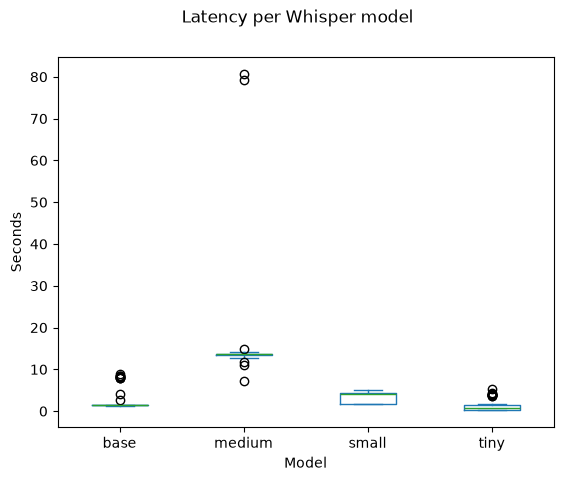

<Axes: title={'center': 'Model ratio of partial transcriptions by duration of transcription'}, xlabel='model', ylabel='Duration (s)'>

<Axes: title={'center': 'Model ratio of partial transcriptions by duration of transcription'}, xlabel='model', ylabel='Duration (s)'>

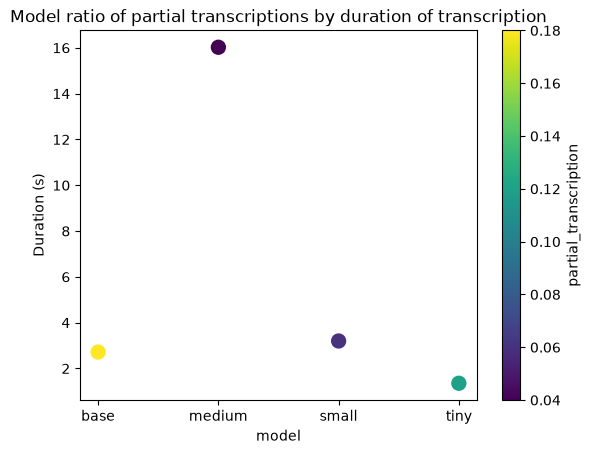

In [ ]:
model_duration_correctness = df_csv.loc[:, ["hypothesis", "reference", "model", "listen_latency (s)" ]]

# Mask by transcription done
m = model_duration_correctness["hypothesis"].isna()
model_duration_correctness["no_transcription"] = m

# Mask by correctness of transcription
m2 = model_duration_correctness["hypothesis"].eq(model_duration_correctness["reference"])
model_duration_correctness["correct_transcription"] = m2

# Mask for partial transcriptions
model_duration_correctness["partial_transcription"] = ~m2 & ~m

detailed_correctness_counts = model_duration_correctness.groupby("model").mean(numeric_only=True).reset_index()

detailed_correctness_counts.plot.scatter(x="model", y="listen_latency (s)",
                                         c="correct_transcription",
                                         s=100,
                                         title="Correct transcriptions by model and duration",
                                         ylabel="Duration (s)",
                                         xlabel="model")          


<Axes: title={'center': 'Model ratio of partial transcriptions by duration of transcription'}, xlabel='model', ylabel='Duration (s)'>

<Axes: title={'center': 'Model ratio of partial transcriptions by duration of transcription'}, xlabel='model', ylabel='Duration (s)'>

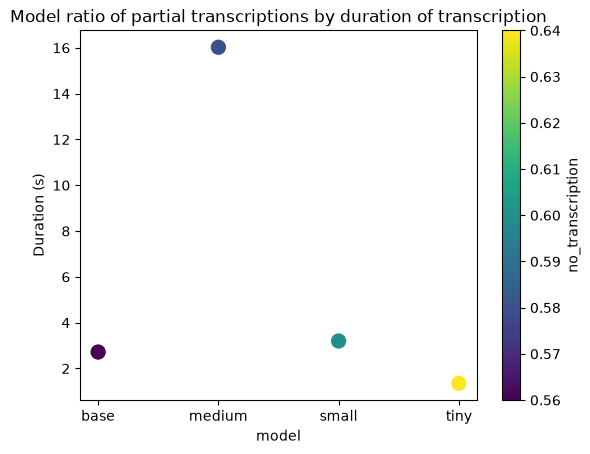

In [ ]:
detailed_correctness_counts.plot.scatter(x="model", y="listen_latency (s)",
                                         c="no_transcription",
                                         s=100,
                                         title="Partial transcriptions by model and duration",
                                         ylabel="Duration (s)",
                                         xlabel="model")

<Axes: title={'center': 'Model ratio of failed transcriptions by duration of transcription'}, xlabel='model', ylabel='Duration (s)'>

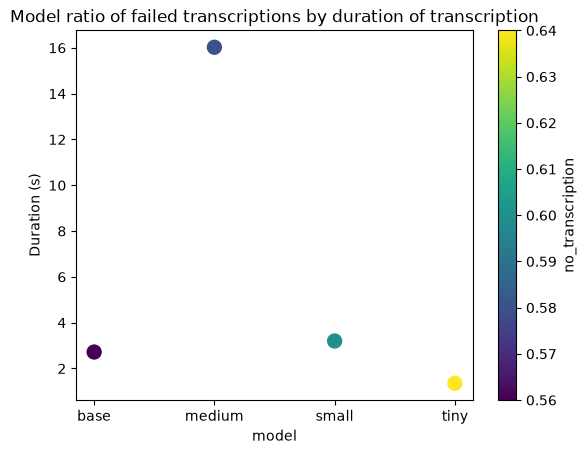

In [ ]:
detailed_correctness_counts.plot.scatter(x="model", y="listen_latency (s)",
                                         c="no_transcription",
                                         s=100,
                                         title="Failed transcriptions by model and duration",
                                         ylabel="Duration (s)",
                                         xlabel="model")         

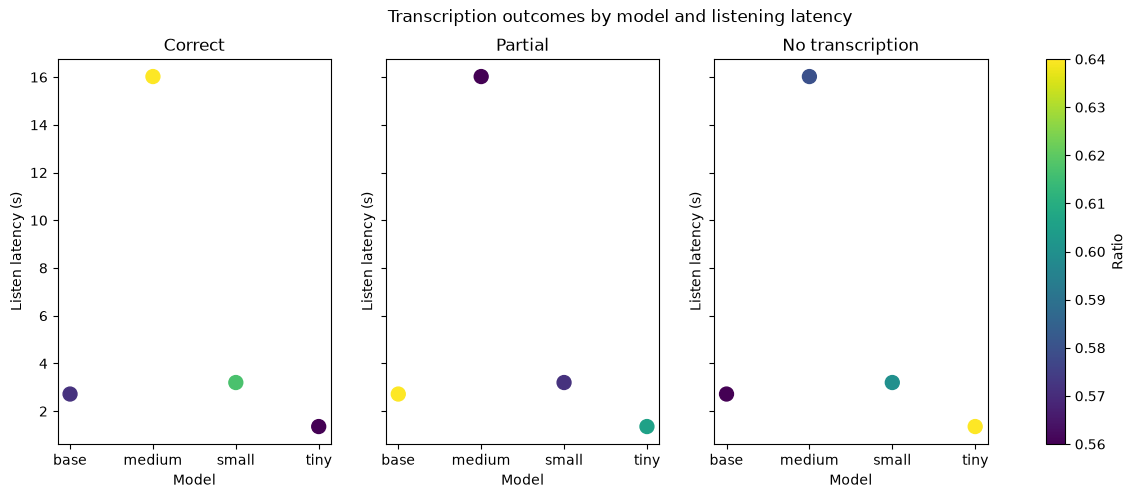

In [ ]:
outcome_ratios = [
    ("correct_transcription", "Correct"),
    ("partial_transcription", "Partial"),
    ("no_transcription", "No transcription"),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharex=True, sharey=True)

for ax, (ratio_column, title) in zip(axes, outcome_ratios):
    points = ax.scatter(
        detailed_correctness_counts["model"],
        detailed_correctness_counts["listen_latency (s)"],
        c=detailed_correctness_counts[ratio_column],
        s=100,
    )
    ax.set_title(title)
    ax.set_xlabel("Model")
    ax.set_ylabel("Listen latency (s)")

fig.colorbar(points, ax=axes, label="Ratio")
fig.suptitle("Transcription outcomes by model and listening latency")
plt.show()